In [1]:
!pip install fredapi

# Import & Setup

In [4]:
 import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from fredapi import Fred
from scipy import stats

fred = Fred(api_key='ab329f8a78c1be7854dadc2d8b280bd3')

# Fetch data

In [7]:
# Fetch the four macroeconomic indicators
gdp        = fred.get_series('GDP',      observation_start='1990-01-01')
cpi        = fred.get_series('CPIAUCSL', observation_start='1990-01-01')
unrate     = fred.get_series('UNRATE',   observation_start='1990-01-01')
fedfunds   = fred.get_series('FEDFUNDS', observation_start='1990-01-01')

# Convert to DataFrame
df_gdp      = gdp.to_frame(name='GDP')
df_cpi      = cpi.to_frame(name='CPI')
df_unrate   = unrate.to_frame(name='Unemployment Rate')
df_fedfunds = fedfunds.to_frame(name='Fed Funds Rate')

# Resample all to quarterly frequency and merge
df = (df_gdp
      .join(df_cpi.resample('QS').mean(), how='outer')
      .join(df_unrate.resample('QS').mean(), how='outer')
      .join(df_fedfunds.resample('QS').mean(), how='outer'))

df = df.dropna()
print(df.shape)
print(df.head())


(145, 4)
                 GDP         CPI  Unemployment Rate  Fed Funds Rate
1990-01-01  5872.701  128.033333           5.300000        8.250000
1990-04-01  5960.028  129.300000           5.333333        8.243333
1990-07-01  6015.116  131.533333           5.700000        8.160000
1990-10-01  6004.733  133.766667           6.133333        7.743333
1991-01-01  6035.178  134.766667           6.600000        6.426667


# Visualization 1 — Time series overview

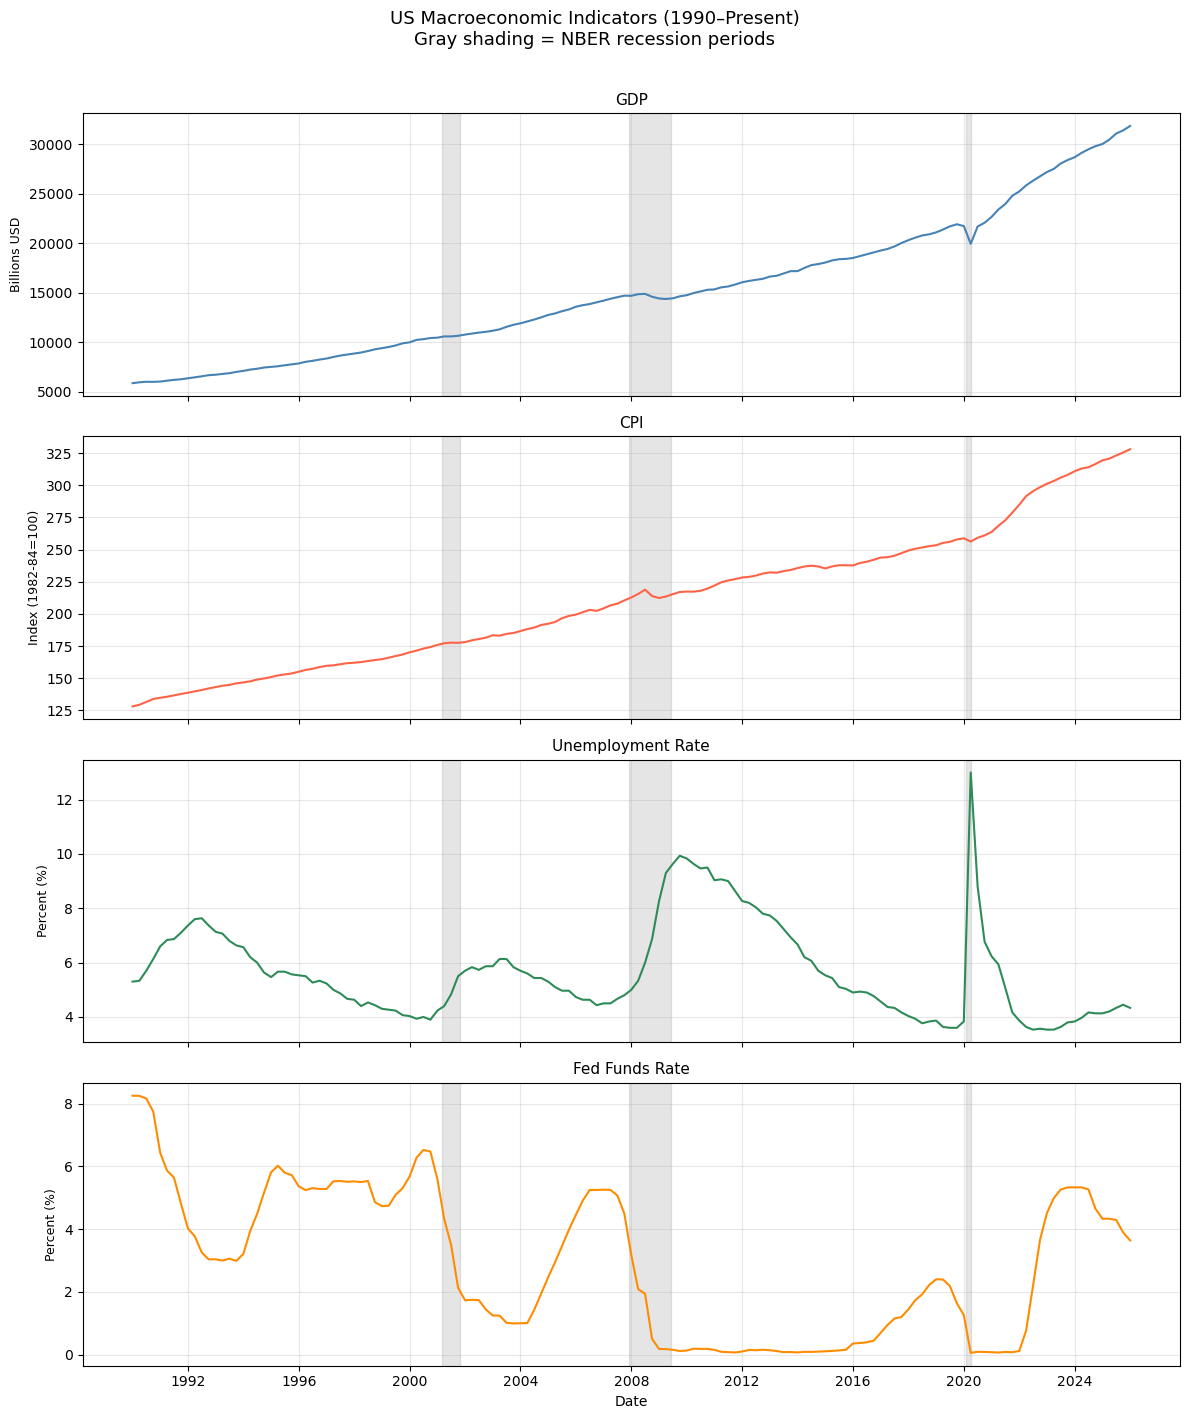

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

series = ['GDP', 'CPI', 'Unemployment Rate', 'Fed Funds Rate']
colors = ['steelblue', 'tomato', 'seagreen', 'darkorange']
ylabels = ['Billions USD', 'Index (1982-84=100)', 'Percent (%)', 'Percent (%)']

for ax, col, color, ylabel in zip(axes, series, colors, ylabels):
    ax.plot(df.index, df[col], color=color, lw=1.5)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(col, fontsize=11)
    ax.grid(True, alpha=0.3)

    # Shade recession periods (approximate)
    recessions = [
        ('2001-03-01', '2001-11-01'),
        ('2007-12-01', '2009-06-01'),
        ('2020-02-01', '2020-04-01'),
    ]
    for start, end in recessions:
        ax.axvspan(start, end, color='gray', alpha=0.2)

axes[-1].set_xlabel('Date')
fig.suptitle('US Macroeconomic Indicators (1990–Present)\nGray shading = NBER recession periods',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('macro_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()


## Time Series Overview

All four indicators reflect the major economic events of the past 35 years. GDP has grown steadily from $5.9 trillion in 1990 to over $30 trillion today, with only brief contractions visible during the 2008–09 financial crisis and the 2020 COVID shock. CPI has risen monotonically, with the steepest acceleration occurring post-2020 — the sharpest inflationary episode since the 1980s. Unemployment spikes sharply at each recession: peaking near 8% in 1992, 10% in 2009, and hitting an extraordinary 13% in Q2 2020 before rapidly recovering. The Fed Funds Rate shows the clearest policy response pattern: cut aggressively at each recession and held near zero for extended periods after 2008 and 2020, then raised sharply post-2022 to combat inflation.

四个指标共同反映了过去35年的主要经济事件。GDP从1990年的5.9万亿美元稳步增长至今超过30万亿美元，仅在2008-09年金融危机和2020年新冠冲击时出现短暂收缩。CPI单调上升，2020年后加速最为明显——这是自1980年代以来最剧烈的通胀周期。失业率在每次衰退时急剧攀升：1992年峰值约8%，2009年约10%，2020年Q2达到惊人的13%后迅速回落。联邦基金利率最清晰地展示了货币政策反应模式：每次衰退时大幅降息，2008年和2020年后长期维持在近零水平，2022年后大幅加息以对抗通胀。

# Visualization 2 — Correlation matrix

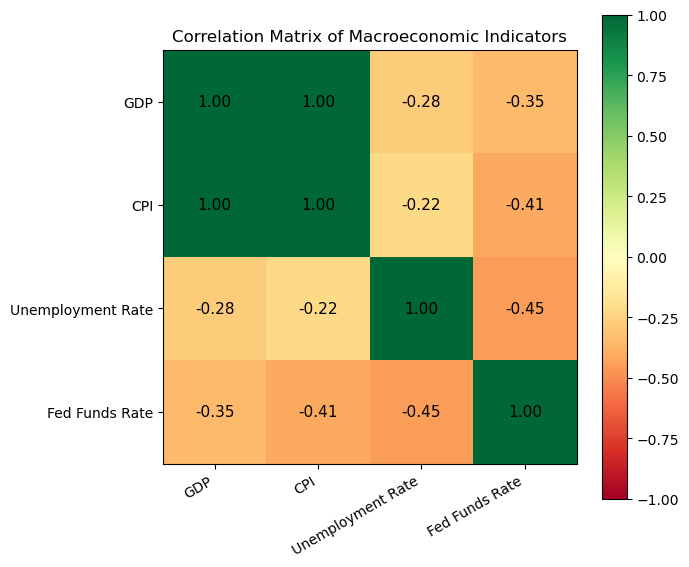

In [14]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=30, ha='right')
ax.set_yticklabels(corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=11,
                color='black')

ax.set_title('Correlation Matrix of Macroeconomic Indicators')
plt.tight_layout()
plt.savefig('macro_correlation.png', dpi=150)
plt.show()


## Correlation Matrix


GDP and CPI show a near-perfect correlation of 1.00 — both are driven by the same long-run nominal growth trend, so this correlation is largely spurious rather than economically meaningful. More interesting are the negative correlations: unemployment is negatively correlated with both GDP (-0.28) and CPI (-0.22), consistent with the idea that higher economic output tends to accompany lower unemployment. The Fed Funds Rate shows the strongest negative correlation with unemployment (-0.45), reflecting the Fed’s mandate to lower rates when unemployment rises. The negative correlation between the Fed Funds Rate and CPI (-0.41) seems counterintuitive but reflects timing: the Fed typically raises rates after inflation has already risen, so over the full sample the rate and price level move in opposite directions.

GDP和CPI的相关系数接近1.00——两者都受相同的长期名义增长趋势驱动，因此这个相关性在很大程度上是伪相关而非真实的经济含义。更有意义的是负相关关系：失业率与GDP（-0.28）和CPI（-0.22）均负相关，符合经济产出较高时失业率较低的直觉。联邦基金利率与失业率的负相关最强（-0.45），反映了美联储在失业率上升时降息的政策使命。联邦基金利率与CPI的负相关（-0.41）看似反直觉，但反映了时间滞后效应：美联储通常在通胀已经上升后才加息，因此在整个样本期内利率与价格水平呈相反方向运动。


# Visualization 3 — Inflation vs. unemployment (Phillips Curve)

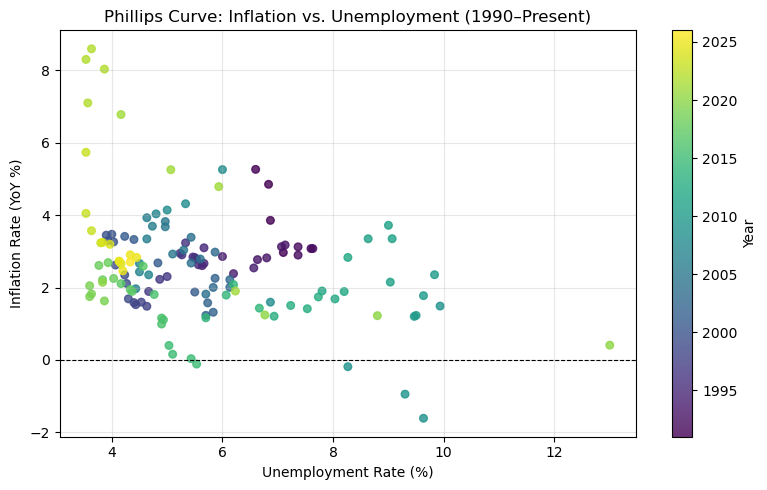

In [17]:
# Compute YoY inflation rate from CPI
df['Inflation'] = df['CPI'].pct_change(4) * 100  # 4 quarters = YoY
df_phillips = df.dropna()

fig, ax = plt.subplots(figsize=(8, 5))
scatter = ax.scatter(df_phillips['Unemployment Rate'],
                     df_phillips['Inflation'],
                     c=df_phillips.index.year,
                     cmap='viridis', s=30, alpha=0.8)
plt.colorbar(scatter, ax=ax, label='Year')

ax.set_xlabel('Unemployment Rate (%)')
ax.set_ylabel('Inflation Rate (YoY %)')
ax.set_title('Phillips Curve: Inflation vs. Unemployment (1990–Present)')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('phillips_curve.png', dpi=150)
plt.show()


## Phillips Curve

The scatter plot reveals that the classical Phillips Curve relationship — high unemployment associated with low inflation — is visible but weak and unstable over this sample. In the 1990s–2000s (purple/blue dots) the relationship is clearer, with unemployment above 6% generally accompanied by lower inflation. However, the 2020s (yellow dots) show a dramatic breakdown: unemployment fell to historic lows near 3.5% while inflation surged above 8%, driven by post-pandemic supply shocks rather than demand-pull forces. The wide scatter across all years confirms that the simple Phillips Curve is an incomplete model of inflation dynamics over longer horizons.

散点图显示，经典菲利普斯曲线关系——高失业率伴随低通胀——在本样本中可见但微弱且不稳定。1990年代至2000年代（紫色/蓝色点）关系更为清晰，失业率超过6%时通胀通常较低。然而，2020年代（黄色点）出现了显著的结构性断裂：失业率降至约3.5%的历史低位，而通胀同时飙升至8%以上，这主要由疫情后的供给侧冲击而非需求拉动引起。所有年份的大范围散点分布证实，简单的菲利普斯曲线在较长时间跨度上是对通胀动态的不完整描述。

# Visualization 4 — Fed Funds Rate vs. Inflation

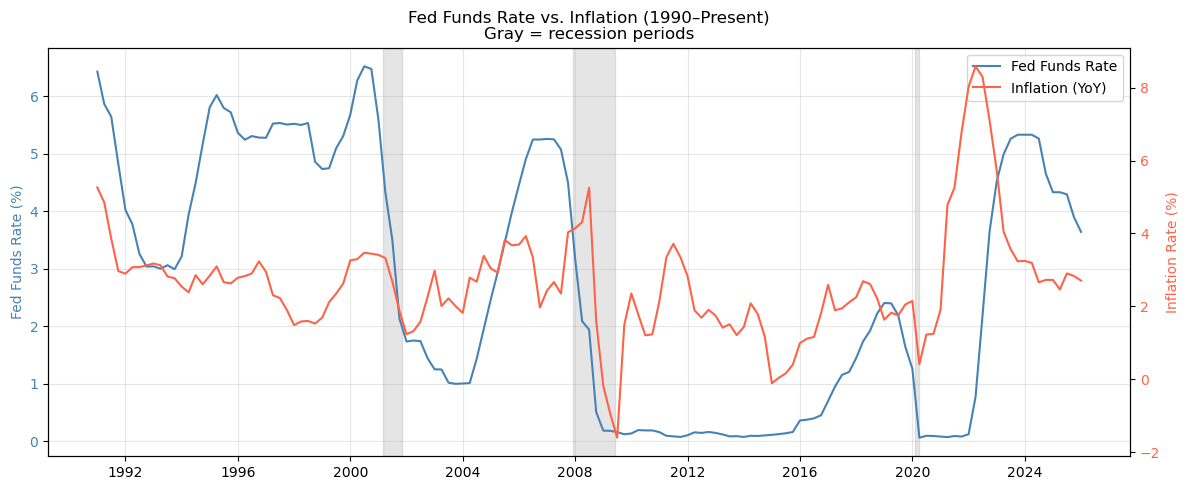

In [20]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df_phillips.index, df_phillips['Fed Funds Rate'],
         color='steelblue', lw=1.5, label='Fed Funds Rate')
ax1.set_ylabel('Fed Funds Rate (%)', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.plot(df_phillips.index, df_phillips['Inflation'],
         color='tomato', lw=1.5, label='Inflation (YoY)')
ax2.set_ylabel('Inflation Rate (%)', color='tomato')
ax2.tick_params(axis='y', labelcolor='tomato')

for start, end in recessions:
    ax1.axvspan(start, end, color='gray', alpha=0.2)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax1.set_title('Fed Funds Rate vs. Inflation (1990–Present)\nGray = recession periods')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fedfunds_vs_inflation.png', dpi=150)
plt.show()


## Fed Funds Rate vs. Inflaction

The dual-axis chart reveals a clear pattern of monetary policy response across three decades. In the early 1990s the Fed cut rates from above 6% as inflation fell. After the dot-com bust (2001) rates were cut to 1% and held low, then raised back to 5% by 2006 before the 2008 crisis triggered another sharp cut to near zero. The most striking episode is post-2020: inflation spiked to over 8% (red) while the Fed initially kept rates at zero, before launching the most aggressive hiking cycle in 40 years, raising the Fed Funds Rate from 0% to over 5% between 2022 and 2023. The chart also shows a persistent lag between inflation rising and the Fed responding — a recurring feature of monetary policy.

双轴图揭示了三十年间清晰的货币政策反应模式。1990年代初，随着通胀下降美联储从6%以上降息。2001年互联网泡沫破裂后利率降至1%并长期维持低位，随后在2008年危机前升至5%，危机后再次大幅降至近零。最引人注目的是2020年后的时期：通胀飙升至8%以上（红色），美联储起初维持零利率，随后启动了40年来最激进的加息周期，联邦基金利率在2022至2023年间从0%升至5%以上。图表还显示了通胀上升与美联储反应之间持续存在的滞后性——这是货币政策的一个反复出现的特征。

# Summary

English:

This project conducts an exploratory analysis of four key US macroeconomic indicators — GDP, CPI, Unemployment Rate, and Federal Funds Rate — sourced directly from the FRED database covering 1990 to present, totalling 145 quarterly observations.

The analysis proceeds in four layers:

1.	The time series overview documents the long-run trends and cyclical behavior of all four indicators, with recession periods shaded to highlight how each variable responds to economic downturns. GDP and CPI show persistent upward trends interrupted by brief contractions, while unemployment and the Fed Funds Rate exhibit sharp cyclical swings tied to recessions and monetary policy decisions;
2.	The correlation matrix quantifies pairwise relationships across the four indicators. The near-perfect GDP-CPI correlation reflects a shared nominal growth trend rather than a causal relationship. More meaningful are the negative correlations between the Fed Funds Rate and both unemployment (-0.45) and CPI (-0.41), consistent with the Fed’s dual mandate of price stability and maximum employment;
3.	The Phillips Curve scatter plot examines the relationship between inflation and unemployment across time. While a negative relationship is visible in earlier decades, the 2021–2022 period shows a clear structural break: unemployment hit historic lows while inflation surged above 8%, driven by post-pandemic supply disruptions rather than demand-pull forces — a pattern inconsistent with the simple Phillips Curve framework;
4.	The Fed Funds Rate vs. Inflation dual-axis chart traces three decades of monetary policy response, highlighting the recurring lag between inflation rising and the Fed reacting, and documenting the most aggressive rate-hiking cycle since the 1980s in 2022–2023.

Overall, the analysis demonstrates how four standard macroeconomic indicators interact across business cycles, and how well-established relationships like the Phillips Curve can break down under structural shocks — illustrating both the power and the limitations of reduced-form empirical macroeconomics.

中文：

本项目对四个美国核心宏观经济指标——GDP、CPI、失业率和联邦基金利率——进行了探索性分析，数据直接来源于 FRED 数据库，覆盖1990年至今，共145个季度观测值。

分析分为四个层次：

1.	时间序列总览记录了四个指标的长期趋势与周期性行为，通过标注衰退区间突出各变量对经济下行的反应。GDP和CPI呈持续上升趋势，仅在衰退期短暂收缩；失业率和联邦基金利率则与经济衰退和货币政策决策紧密联动，呈现明显的周期性波动；
2.	相关矩阵量化了四个指标之间的两两关系。GDP与CPI近乎完美的相关性反映的是共同的名义增长趋势而非因果关系。更有意义的是联邦基金利率与失业率（-0.45）和CPI（-0.41）的负相关，与美联储价格稳定和充分就业的双重使命相符；
3.	菲利普斯曲线散点图考察了通胀与失业率在不同时期的关系。早期年份可见明显的负相关，但2021-2022年出现了清晰的结构性断裂：失业率创历史新低的同时通胀飙升至8%以上，由疫情后的供给侧冲击而非需求拉动驱动——这一模式与简单菲利普斯曲线框架不符；
4.	联邦基金利率与通胀双轴图追踪了三十年的货币政策反应，揭示了通胀上升与美联储反应之间反复出现的滞后性，并记录了2022-2023年自1980年代以来最激进的加息周期。

整体而言，本分析展示了四个标准宏观经济指标在经济周期中的相互作用，以及菲利普斯曲线等成熟关系在结构性冲击下如何失效——既体现了简化式实证宏观经济分析的价值，也揭示了其局限性。
